# Project - 1 E-Commerce Sales & Customer Behavior Analysis

<img src="https://i.postimg.cc/QM51dqH4/E-Commerce-Sales.jpg" height="500" width="600"/><br>

# Data Overview

* The online retail company wants to understand its sales performance and customer purchasing behaviour.

* The dataset contains details about each transaction, such as invoice number, product code, product description, quantity purchased, invoice date, unit price, customer ID, and country.

* EDA is carried out on the given dataset to analyse product sales, customer purchases, revenue, and sales trends using different visualizations.

* Insights are drawn from the visualizations to understand which products sell the most, which countries generate more revenue, and how customers purchase products.

* Finally, performing Exploratory Data Analysis helps us understand the sales patterns, customer behaviour, and overall business performance of the online retail company.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore') 

## To read the dataset

In [3]:
df=pd.read_excel('Online Retail 11.00.05 PM.xlsx')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


## To Clean and Understand the dataset 

#### 1) Number of ROWS & COLUMNS.

In [5]:
 df.shape

(541909, 8)

#### 2) The list of index value counts and column names.

In [6]:
print(df.index,df.columns,sep="\n")

RangeIndex(start=0, stop=541909, step=1)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


#### 3) Identification of Missing values and DATA Type, simultaneously.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

#### 4) To find the Number of duplicate values

In [12]:
df.duplicated().sum()

np.int64(5268)

In [13]:
df.duplicated().value_counts()

False    536641
True       5268
Name: count, dtype: int64

In [19]:
df['Country'].value_counts()

Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


#### 5) To find the number of unique values

In [14]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [18]:
df['InvoiceNo'].nunique()

25900

In [17]:
df['StockCode'].nunique()

4070

#### 6) To describe the dataset

In [22]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [23]:
df.describe(include='object')

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


#### 7) Identify cancelled transactions

In [20]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

df['Cancelled'] = df['InvoiceNo'].str.startswith('C')

df['Cancelled'].value_counts()

Cancelled
False    532621
True       9288
Name: count, dtype: int64

#### 8) Create a sales column

In [31]:
df['Sales'] = df['Quantity'] * df['UnitPrice']
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Cancelled', 'Sales'],
      dtype='object')

#### 9) Create a clean dataset for sales analysis

In [93]:
sales_df = df[
    (df['Cancelled'] == False) &
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0)
].copy()

In [94]:
sales_df.shape

(530104, 10)

In [95]:
sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Cancelled,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34


In [96]:
sales_df['Cancelled'].value_counts()

Cancelled
False    530104
Name: count, dtype: int64

In [97]:
sales_df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,530104.000000,530104.000000
mean,10.542037,3.907625
std,155.524124,35.915681
min,1.000000,0.001000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,13541.330000


#### 10) Extract date-related information

In [98]:
import datetime as dt

sales_df['InvoiceDate'] = pd.to_datetime(sales_df['InvoiceDate'])

sales_df['Year'] = sales_df['InvoiceDate'].dt.year

sales_df['Month'] = sales_df['InvoiceDate'].dt.month

sales_df['MonthName'] = sales_df['InvoiceDate'].dt.strftime('%b')

sales_df['Week'] = sales_df['InvoiceDate'].dt.isocalendar().week

sales_df['Day'] = sales_df['InvoiceDate'].dt.day_name()

sales_df['Hour'] = sales_df['InvoiceDate'].dt.hour

In [99]:
sales_df[['InvoiceDate', 'Year', 'Month', 'MonthName',
          'Week', 'Day', 'Hour']].head()

,InvoiceDate,Year,Month,MonthName,Week,Day,Hour
0,2010-12-01 08:26:00,2010,12,Dec,48,Wednesday,8
1,2010-12-01 08:26:00,2010,12,Dec,48,Wednesday,8
2,2010-12-01 08:26:00,2010,12,Dec,48,Wednesday,8
3,2010-12-01 08:26:00,2010,12,Dec,48,Wednesday,8
4,2010-12-01 08:26:00,2010,12,Dec,48,Wednesday,8


In [100]:
sales_df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Cancelled', 'Sales', 'Year',
       'Month', 'MonthName', 'Week', 'Day', 'Hour'],
      dtype='object')

## Dataset Cleaning 

### 1) Highest sales generated product

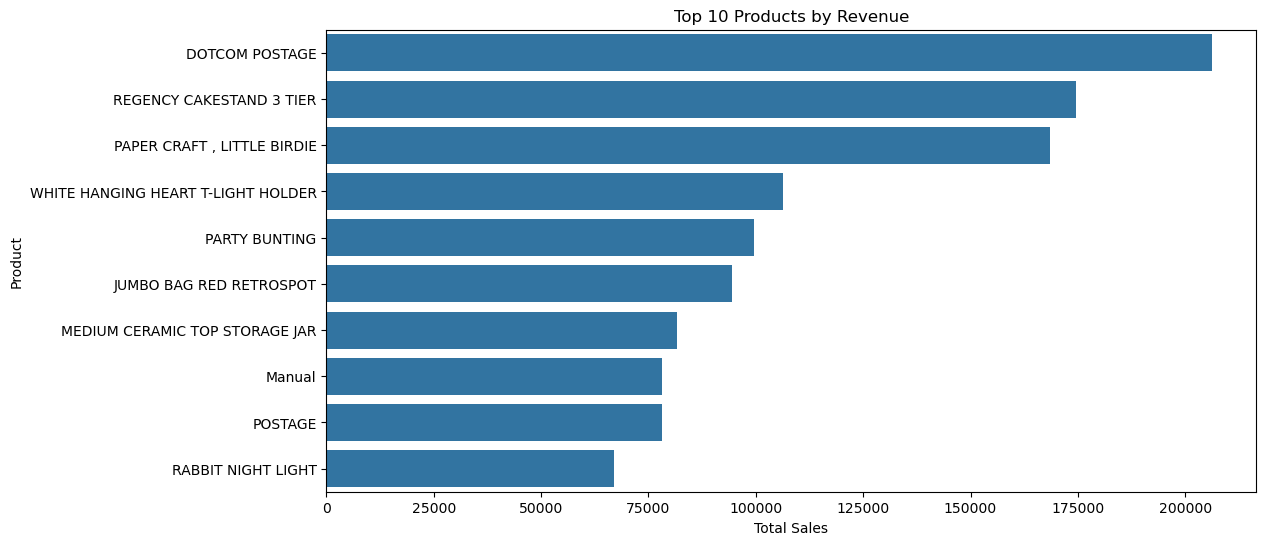

In [40]:
product_sales = sales_df.groupby('Description')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=product_sales.values, y=product_sales.index)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Sales')
plt.ylabel('Product')

plt.show()

Plot 1 – Top 10 Products by Revenue (Bar Plot)

- DOTCOM POSTAGE generated the highest recorded revenue, followed by Regency Cake Stand 3 Tier and Paper Craft, Little Birdie.
- Several decorative and household products also contributed significantly to revenue.
- Some high-revenue entries represent postage or service-related charges rather than physical products.

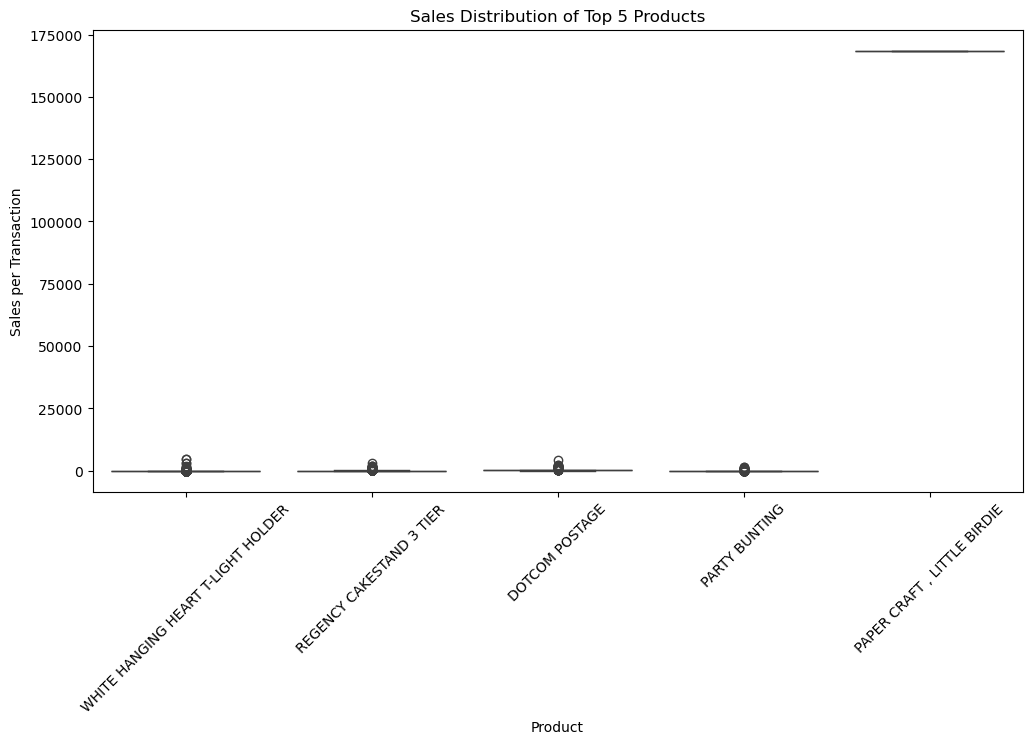

In [41]:
top_products = sales_df.groupby('Description')['Sales'].sum().nlargest(5).index

top_product_df = sales_df[sales_df['Description'].isin(top_products)]

plt.figure(figsize=(12,6))

sns.boxplot(data=top_product_df, x='Description', y='Sales')

plt.title('Sales Distribution of Top 5 Products')
plt.xlabel('Product')
plt.ylabel('Sales per Transaction')

plt.xticks(rotation=45)

plt.show()

Plot 2 – Sales Distribution of Top 5 Products (Box Plot)

- Sales values vary considerably across the top five revenue-generating entries.
- Some products show a wider spread in transaction-level sales.
- A few unusually large transactions influence the distribution, particularly for Paper Craft, Little Birdie.

### 2) The most revenue contributed countries

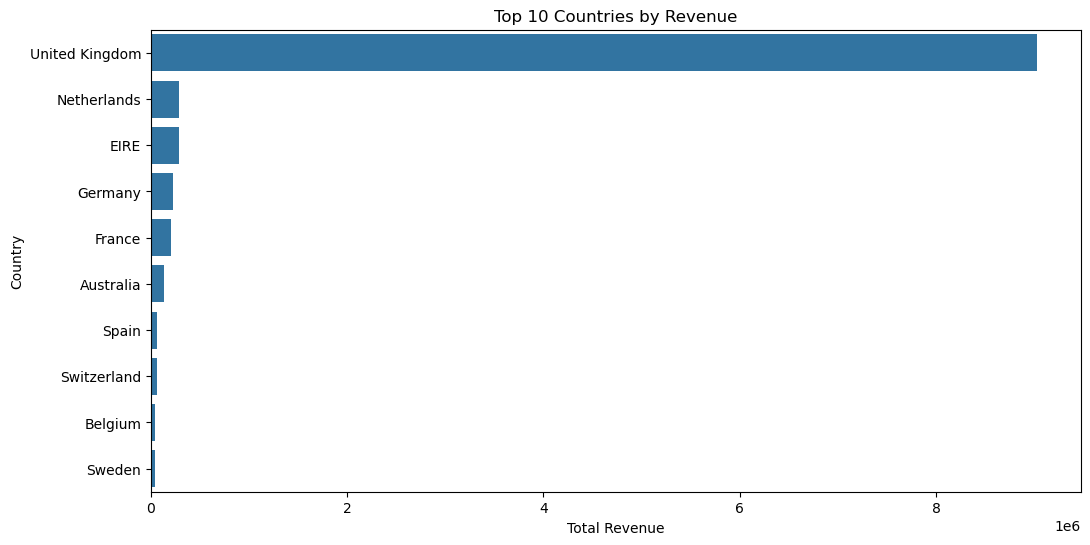

In [42]:
country_sales = sales_df.groupby('Country')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=country_sales.values, y=country_sales.index)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')

plt.show()

Plot 3 – Top 10 Countries by Revenue (Bar Plot)

- The United Kingdom contributes the largest share of total revenue.
- The Netherlands, EIRE, Germany and France are the next major contributors.
- Revenue from the remaining countries is comparatively smaller.
- The business is highly dependent on its UK market.

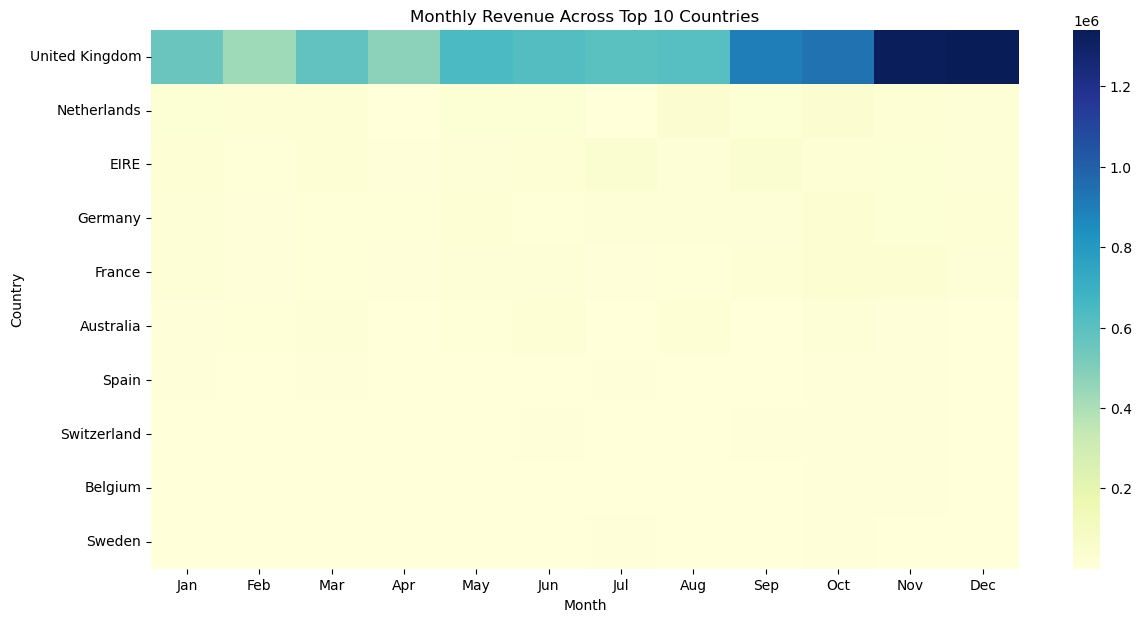

In [43]:
country_month = sales_df.pivot_table(
    index='Country',
    columns='MonthName',
    values='Sales',
    aggfunc='sum',
    fill_value=0
)

top_countries = sales_df.groupby('Country')['Sales'].sum().nlargest(10).index

country_month = country_month.loc[top_countries]

month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

country_month = country_month.reindex(columns=month_order)

plt.figure(figsize=(14,7))

sns.heatmap(country_month, cmap='YlGnBu')

plt.title('Monthly Revenue Across Top 10 Countries')
plt.xlabel('Month')
plt.ylabel('Country')

plt.show()

Plot 4 – Monthly Revenue Across Top 10 Countries (Heatmap)

- The United Kingdom records substantially higher revenue than the other countries across the months.
- Revenue contributions vary across countries and months.
- The heatmap helps identify differences in monthly sales activity across major markets.

## 3) The monthly/weekly sales trends

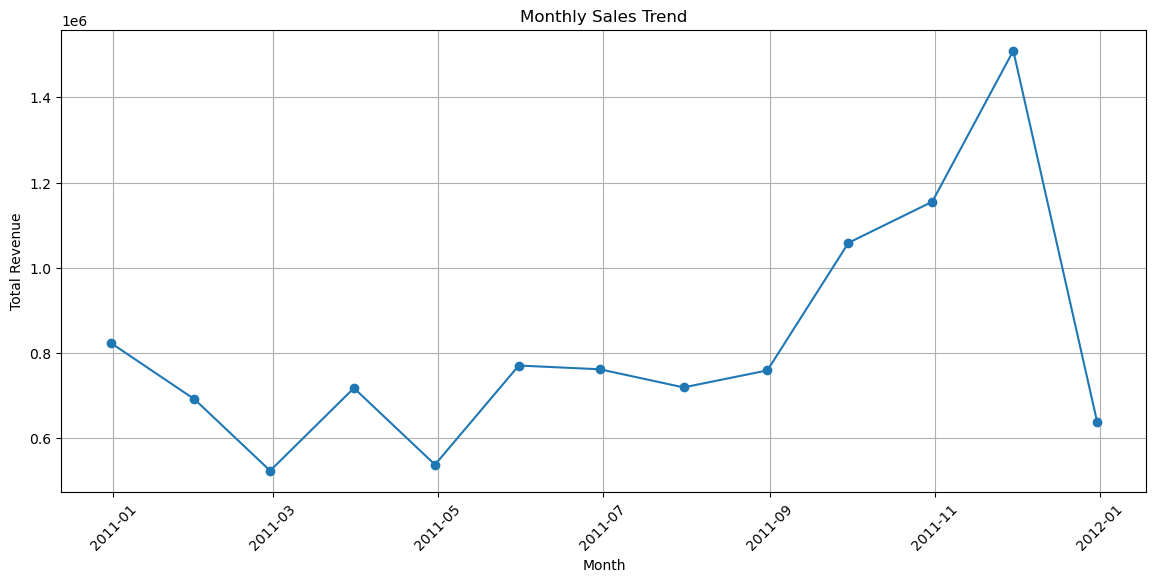

In [68]:
monthly_sales = sales_df.set_index('InvoiceDate').resample('ME')['Sales'].sum()

plt.figure(figsize=(14,6))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)

plt.grid()

plt.show()

In [69]:
# For weekly trends, change 'ME' to 'W':

weekly_sales = sales_df.set_index('InvoiceDate').resample('W')['Sales'].sum()

Plot 5 – Monthly Sales Trend (Time-Series Plot)

- Monthly revenue fluctuates throughout the observation period.
- Sales increase considerably during September, October and November 2011.
- November 2011 records the highest monthly revenue.
- December 2011 shows a decline, but the dataset ends on December 9, so it does not represent a complete month.

##  4) The highest quantity sold product

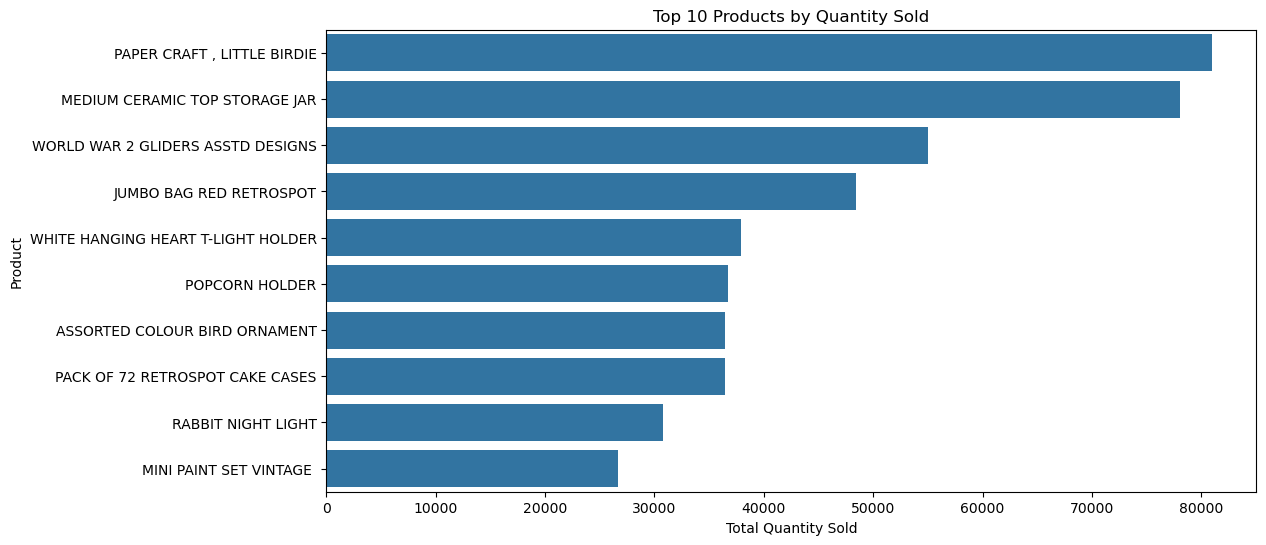

In [70]:
product_quantity = sales_df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=product_quantity.values, y=product_quantity.index)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')

plt.show()

Plot 6 – Top 10 Products by Quantity Sold (Bar Plot)

- Paper Craft, Little Birdie records the highest total quantity sold.
- Medium Ceramic Top Storage Jar and World War 2 Gliders are also among the highest-selling products by quantity.
- These results show that products with the highest quantity sold are not necessarily the same as those generating the highest revenue.
- Some unusually large individual orders influence the ranking.

## 5) Average order value

#### (Average Order Value (AOV) is the average revenue generated per invoice.)

In [71]:
order_sales = sales_df.groupby('InvoiceNo')['Sales'].sum()

average_order_value = order_sales.mean()

print('Average Order Value:', average_order_value)

Average Order Value: 534.403033266533


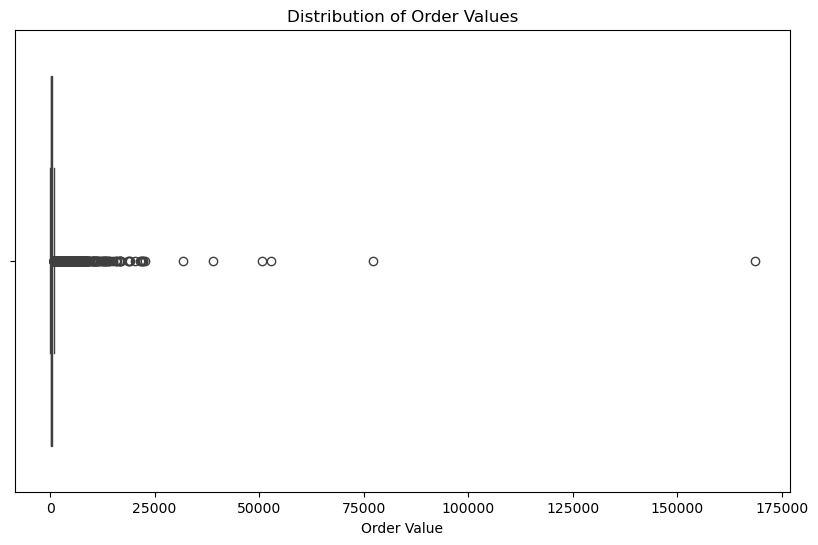

In [72]:
plt.figure(figsize=(10,6))

sns.boxplot(x=order_sales)

plt.title('Distribution of Order Values')
plt.xlabel('Order Value')

plt.show()

Plot 7 – Distribution of Order Values (Box Plot) 

- The average order value is approximately 534.40.
- The median order value is approximately 303.84.
- The average is higher than the median, indicating that some high-value orders influence the average.
- Most orders have comparatively lower values, while a few large orders create outliers.

## 6) The most valuable customers

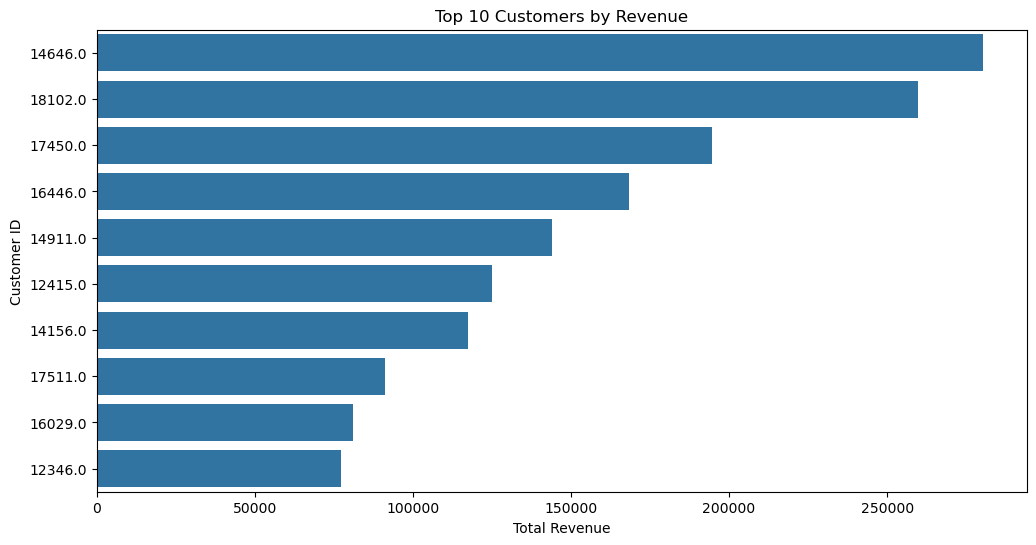

In [73]:
customer_sales = sales_df.groupby('CustomerID')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

sns.barplot(x=customer_sales.values, y=customer_sales.index.astype(str))

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Customer ID')

plt.show()

Plot 8 – Top 10 Customers by Revenue (Bar Plot) 
- Customer ID 14646 contributes the highest recorded revenue.
- Customer IDs 18102 and 17450 are also among the highest-value customers.
- A relatively small group of customers contributes substantial revenue.
- These customers represent important contributors to the business's sales.

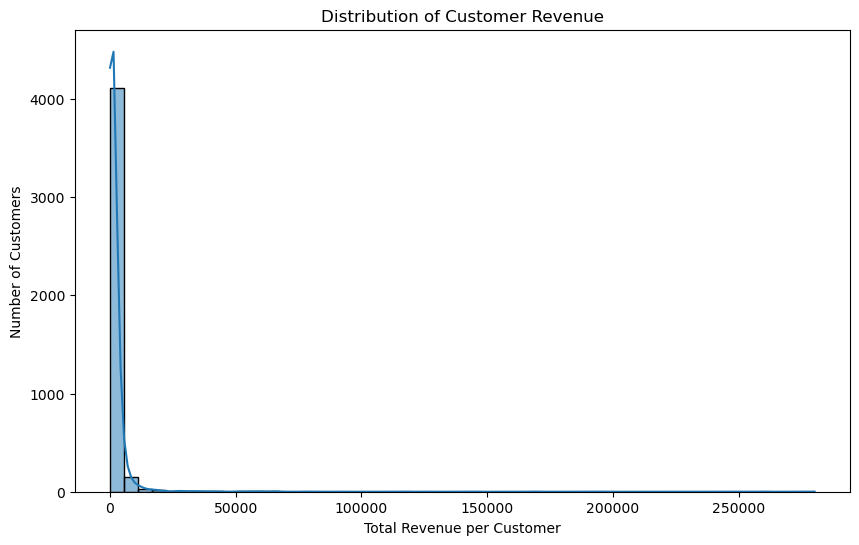

In [74]:
all_customer_sales = sales_df.groupby('CustomerID')['Sales'].sum()

plt.figure(figsize=(10,6))

sns.histplot(all_customer_sales, bins=50, kde=True)

plt.title('Distribution of Customer Revenue')
plt.xlabel('Total Revenue per Customer')
plt.ylabel('Number of Customers')

plt.show()

Plot 9 – Distribution of Customer Revenue (Histogram)

- Most customers contribute comparatively lower revenue.
- Only a smaller group of customers generates very high revenue.
- The distribution is positively skewed, indicating an unequal distribution of revenue across customers.

## 7) Unusual transactions or outliers

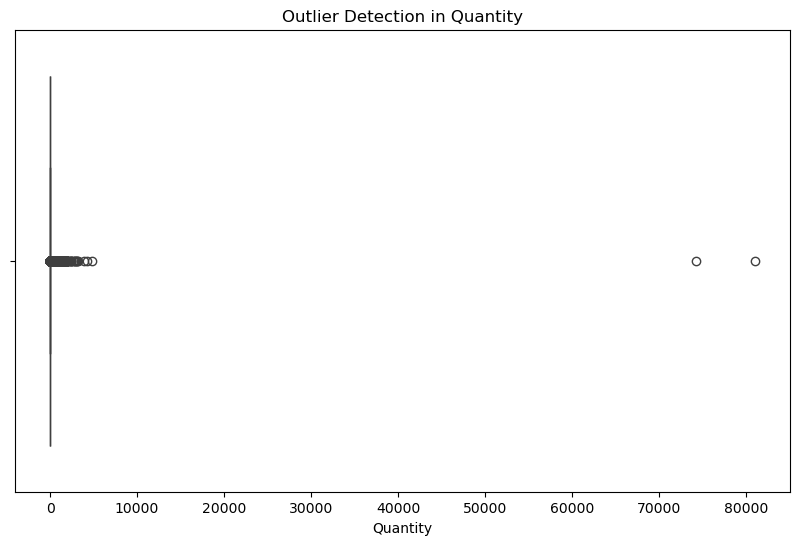

In [75]:
plt.figure(figsize=(10,6))

sns.boxplot(x=sales_df['Quantity'])

plt.title('Outlier Detection in Quantity')
plt.xlabel('Quantity')

plt.show()

Plot 10 – Outlier Detection in Quantity (Box Plot)

- The quantity distribution contains several extreme values.
- Most transactions involve relatively small quantities.
- A few transactions contain unusually large quantities, which significantly affect the distribution.
- These transactions should be investigated before drawing conclusions about normal purchasing behaviour.


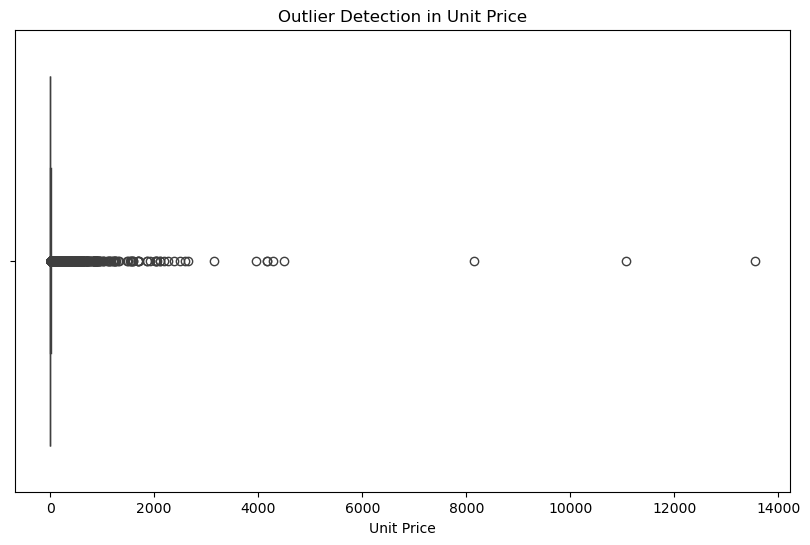

In [76]:
plt.figure(figsize=(10,6))

sns.boxplot(x=sales_df['UnitPrice'])

plt.title('Outlier Detection in Unit Price')
plt.xlabel('Unit Price')

plt.show()

Plot 11 – Outlier Detection in Unit Price (Box Plot)

- Most products have relatively low unit prices.
- A few transactions contain exceptionally high unit prices.
- These extreme values may represent special charges, unusual entries or high-value items.
- Such observations require further investigation.

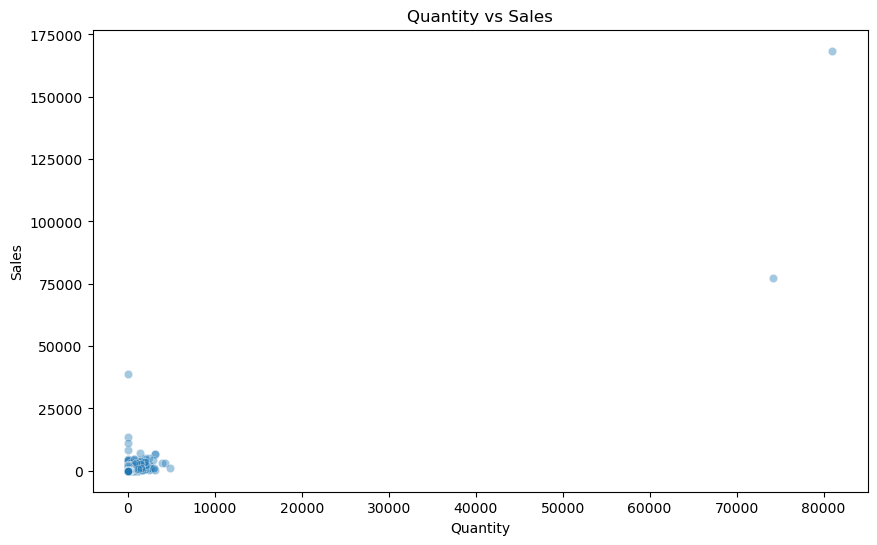

In [77]:
plt.figure(figsize=(10,6))

sns.scatterplot(data=sales_df, x='Quantity', y='Sales', alpha=0.4)

plt.title('Quantity vs Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')

plt.show()

Plot 12 – Quantity vs Sales (Scatter Plot)

- Sales generally increase with the quantity purchased because sales are calculated as quantity multiplied by unit price.
- Higher quantities can produce larger transaction values.
- Some transactions appear far away from the main cluster due to unusually large quantities or prices.

## 8) Percentage of transactions are cancelled

In [78]:
# Calculation of cancellation percentage

total_transactions = df['InvoiceNo'].nunique()

cancelled_transactions = df.loc[df['Cancelled'], 'InvoiceNo'].nunique()

cancellation_percentage = (cancelled_transactions / total_transactions) * 100

print('Total Transactions:', total_transactions)

print('Cancelled Transactions:', cancelled_transactions)

print('Cancellation Percentage:', cancellation_percentage)

Total Transactions: 25900
Cancelled Transactions: 3836
Cancellation Percentage: 14.810810810810812


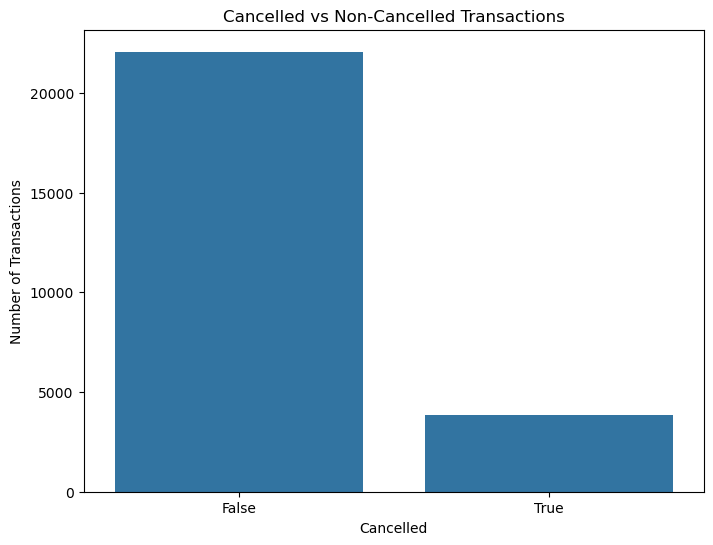

In [79]:
invoice_status = df[['InvoiceNo', 'Cancelled']].drop_duplicates()

plt.figure(figsize=(8,6))

sns.countplot(data=invoice_status, x='Cancelled')

plt.title('Cancelled vs Non-Cancelled Transactions')
plt.xlabel('Cancelled')
plt.ylabel('Number of Transactions')

plt.show()

Plot 13 – Cancelled vs Non-Cancelled Transactions (Count Plot)

- Non-cancelled transactions form the majority of recorded invoices.
- Approximately 14.81% of unique invoices are cancelled.
- Cancelled transactions represent a noticeable portion of the recorded invoice activity.
- The business should examine cancellation patterns to understand possible reasons for cancelled orders.

## 9) The products that show increasing or declining demand

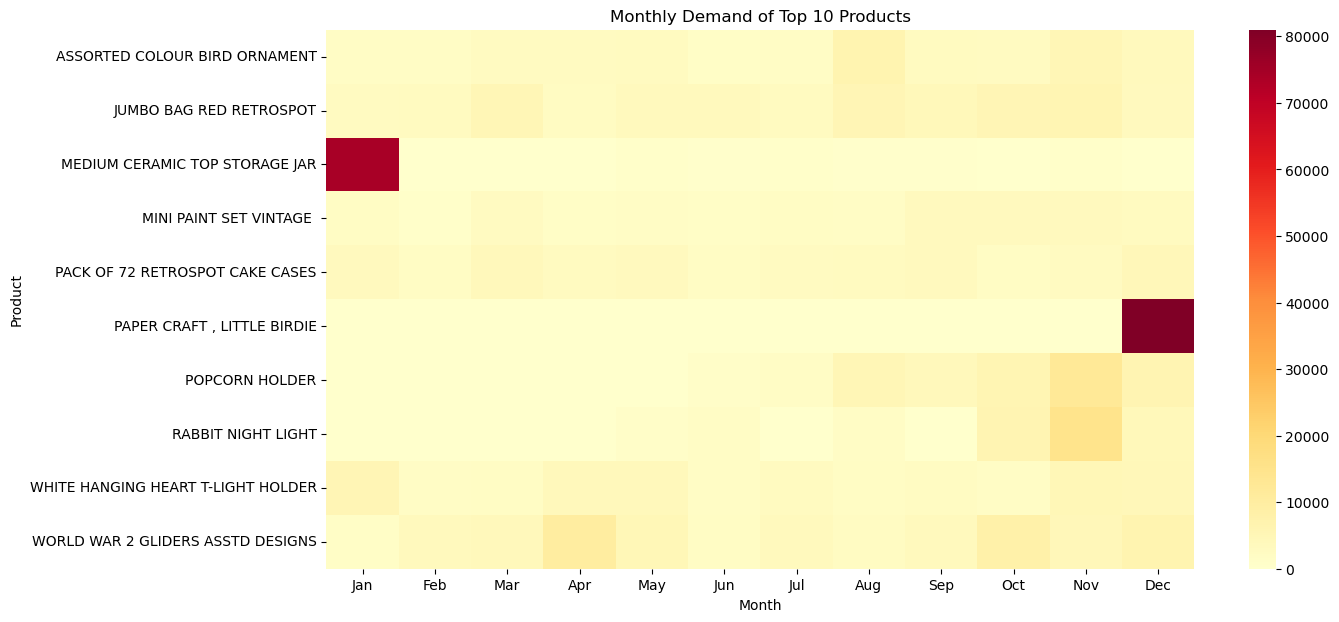

In [80]:
top_10_products = sales_df.groupby('Description')['Quantity'].sum().nlargest(10).index

product_monthly = sales_df[sales_df['Description'].isin(top_10_products)].pivot_table(
    index='Description',
    columns='MonthName',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

product_monthly = product_monthly.reindex(columns=month_order)

plt.figure(figsize=(14,7))

sns.heatmap(product_monthly, cmap='YlOrRd')

plt.title('Monthly Demand of Top 10 Products')
plt.xlabel('Month')
plt.ylabel('Product')

plt.show()

Plot 14 – Monthly Demand of Top 10 Products (Heatmap)

- Product demand varies considerably across the months.
- Some products show higher sales quantities during particular months.
- Paper Craft, Little Birdie and Medium Ceramic Top Storage Jar have unusually large quantity spikes that influence the heatmap.
- These spikes should be checked against individual transactions before interpreting them as genuine increases in demand.
  

<Figure size 1400x600 with 0 Axes>

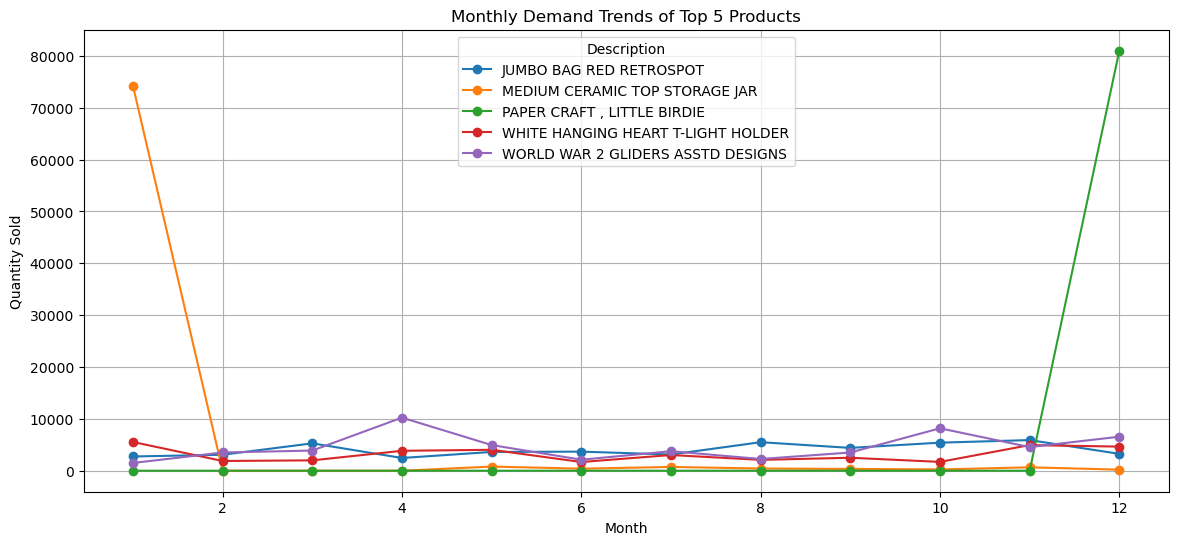

In [81]:
top_5_products = sales_df.groupby('Description')['Quantity'].sum().nlargest(5).index

product_trend = sales_df[sales_df['Description'].isin(top_5_products)].pivot_table(
    index='Month',
    columns='Description',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

plt.figure(figsize=(14,6))

product_trend.plot(figsize=(14,6), marker='o')

plt.title('Monthly Demand Trends of Top 5 Products')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')

plt.grid()

plt.show()

Plot 15 – Monthly Demand Trends of Top 5 Products (Line Plot)

- The monthly quantity sold varies across products.
- Some products show fluctuations rather than a consistent increase or decrease.
- A few unusually large transactions create sharp spikes in the product trends.
- Consistent demand patterns should be evaluated separately from one-time bulk purchases.

## 10) Relationship between product price and quantity purchased

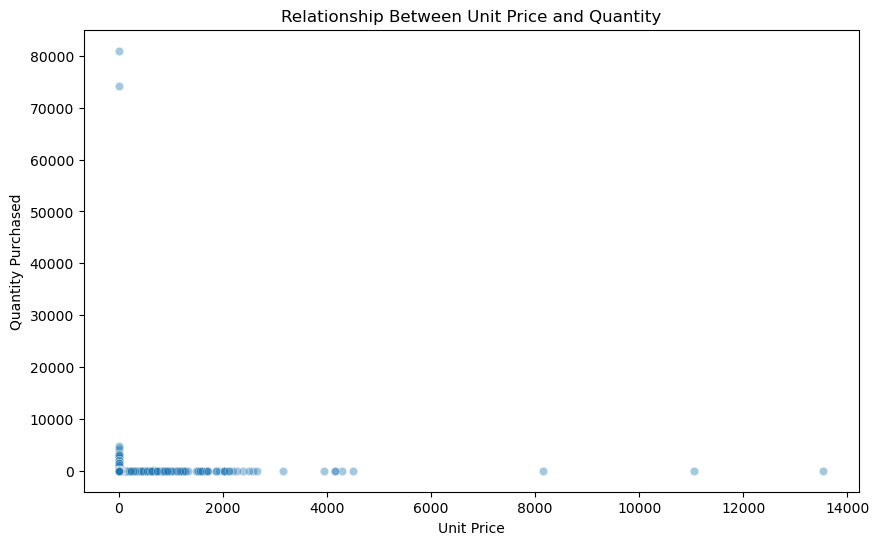

In [64]:
plt.figure(figsize=(10,6))

sns.scatterplot(data=sales_df, x='UnitPrice', y='Quantity', alpha=0.4)

plt.title('Relationship Between Unit Price and Quantity')
plt.xlabel('Unit Price')
plt.ylabel('Quantity Purchased')

plt.show()

Plot 16 – Unit Price vs Quantity (Scatter Plot)

- Most purchases are concentrated around relatively low unit prices and small quantities.
- The scatter plot does not show a clear linear relationship between unit price and quantity purchased.
- Some high-quantity purchases occur at relatively low unit prices.
- Further analysis is required to understand purchasing behaviour across different price ranges.

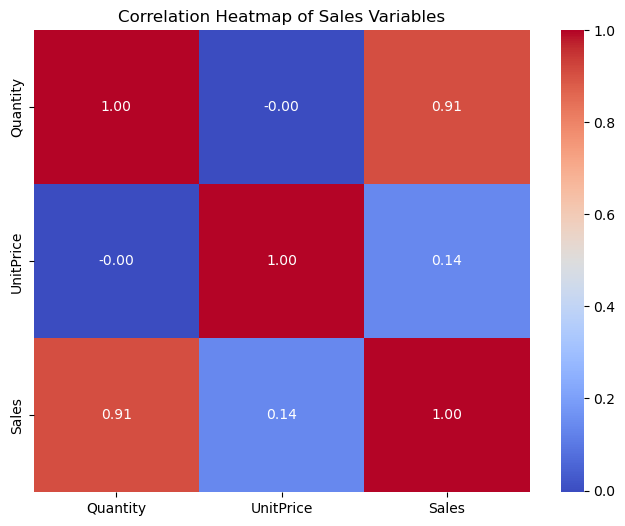

In [65]:
corr_df = sales_df[['Quantity', 'UnitPrice', 'Sales']].copy()

corr = corr_df.corr()

plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap of Sales Variables')

plt.show()

Plot 17 – Correlation Heatmap of Sales Variables

- Quantity and Sales show a strong positive correlation.
- Unit Price and Quantity show almost no linear correlation.
- Unit Price and Sales show a weak positive correlation.
- The strong relationship between Quantity and Sales is expected because Sales is calculated using Quantity multiplied by Unit Price.


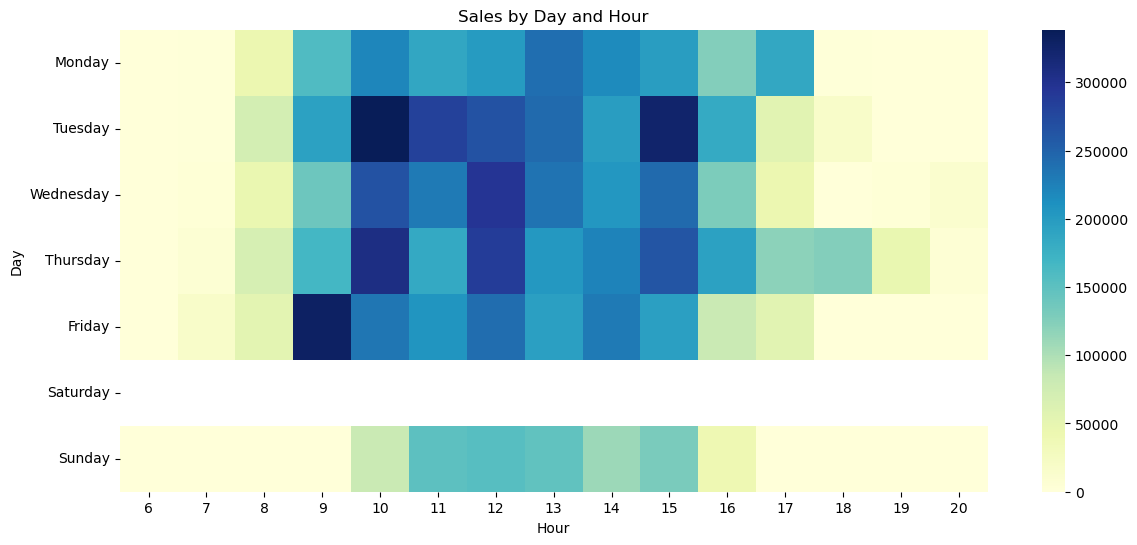

In [66]:
# Heatmap: Sales by weekday and hour

weekday_hour = sales_df.pivot_table(
    index='Day',
    columns='Hour',
    values='Sales',
    aggfunc='sum',
    fill_value=0
)

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

weekday_hour = weekday_hour.reindex(day_order)

plt.figure(figsize=(14,6))

sns.heatmap(weekday_hour, cmap='YlGnBu')

plt.title('Sales by Day and Hour')
plt.xlabel('Hour')
plt.ylabel('Day')

plt.show()

Plot 18 – Sales by Day and Hour (Heatmap)

- Sales activity varies across weekdays and hours.
- Tuesday and Thursday record relatively high overall revenue.
- Several higher-revenue periods occur during normal business hours.
- Saturday has no recorded sales activity in the dataset.


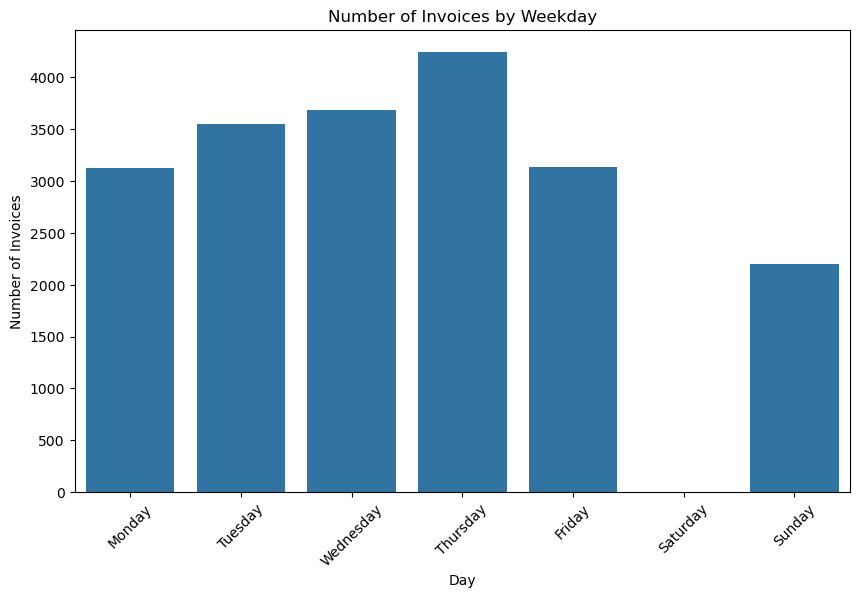

In [83]:
# Count plot: Number of invoices by weekday

invoice_days = sales_df[['InvoiceNo', 'Day']].drop_duplicates()

plt.figure(figsize=(10,6))

sns.countplot(data=invoice_days, x='Day', order=day_order)

plt.title('Number of Invoices by Weekday')
plt.xlabel('Day')
plt.ylabel('Number of Invoices')

plt.xticks(rotation=45)

plt.show()

Plot 19 – Number of Invoices by Weekday (Count Plot)

- Thursday records the highest number of invoices.
- Wednesday and Tuesday also show substantial transaction activity.
- Sunday records fewer invoices than the other active weekdays.
- No Saturday invoices are recorded in the dataset.


## Overall conclusion: 

- The Exploratory Data Analysis of the Online Retail dataset revealed that the United Kingdom contributes the majority of the business revenue, while a few products and customers account for a substantial share of sales. Monthly sales show fluctuations, with higher revenue recorded towards the end of 2011. The analysis also identified differences between products with high revenue and those with high quantities sold.

- Customer purchasing patterns show that most customers generate relatively low revenue, while a smaller group contributes significantly to overall sales. The dataset contains unusual transactions and outliers in quantity and unit price, which require further investigation. Cancelled invoices also represent a noticeable portion of recorded transactions.

- Overall, the analysis provides insights into product performance, customer contributions, geographical revenue distribution, sales trends and purchasing behaviour. These findings can help the business understand its sales performance and identify areas for further investigation and improvement.